In [24]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Tentukan direktori folder tempat gambar berada (gunakan '.' jika di folder yang sama dengan file .ipynb)
folder_path = "."  # Ganti dengan nama folder jika ditaruh di dalam subfolder, misal: "dataset_ijazah"

# Ambil semua file gambar berformat .jpg (atau .png) di dalam folder
extensions = (".jpg", ".jpeg", ".png")
image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(extensions)]

print(f"Ditemukan {len(image_files)} gambar untuk diproses.")



Ditemukan 9 gambar untuk diproses.



Memproses Gambar: 01_HighQuality_Enhanced.jpg


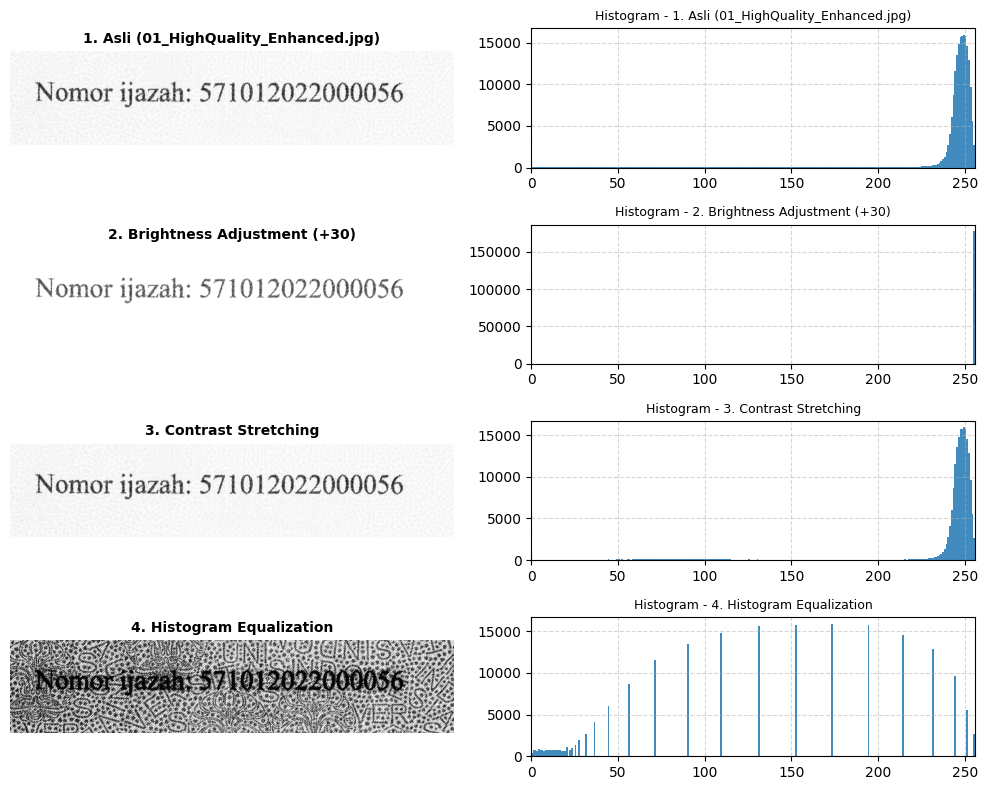


Memproses Gambar: 02_LowContrast.jpg


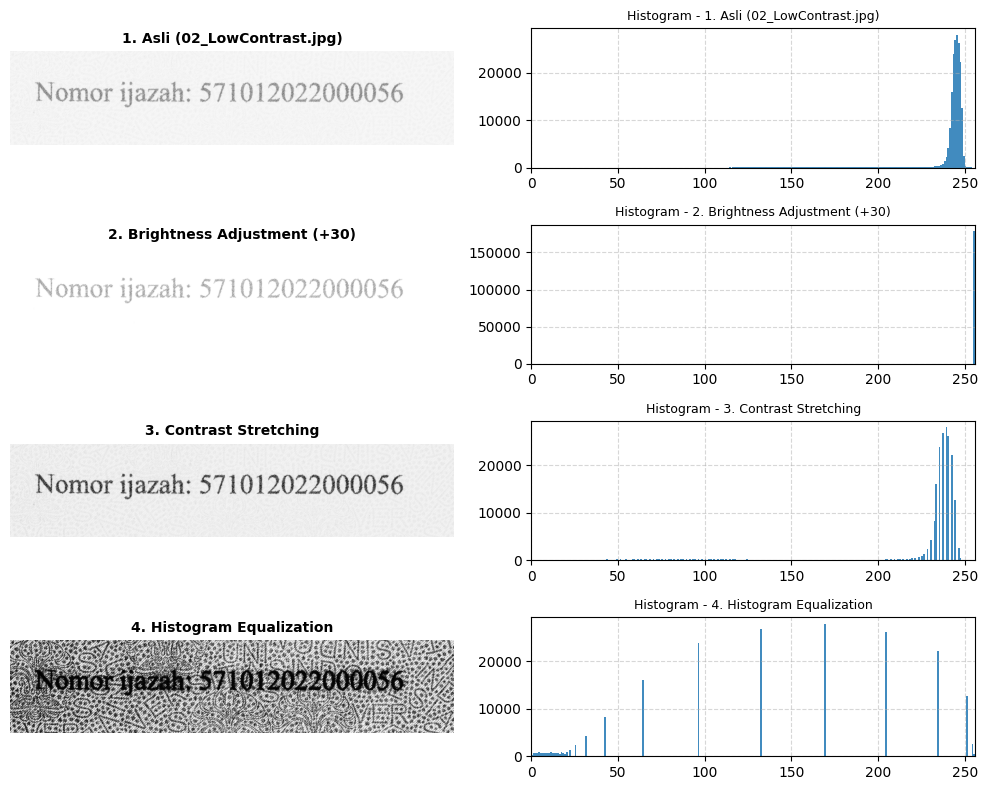


Memproses Gambar: 03_Blurred.jpg


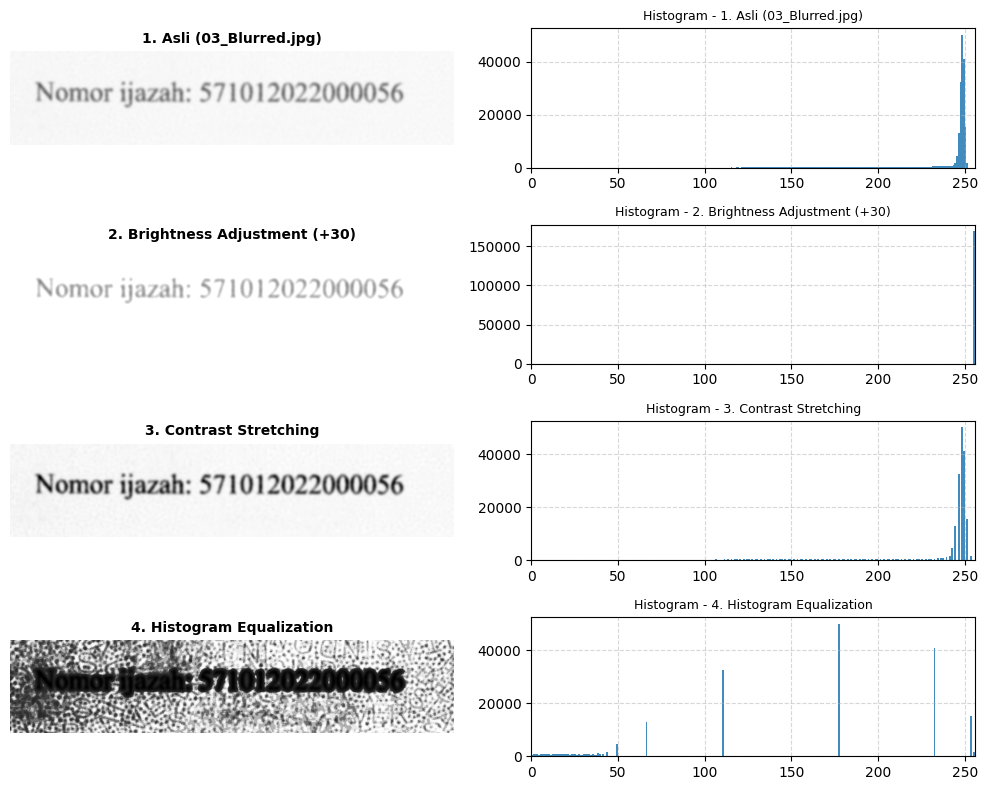


Memproses Gambar: 04_HighNoise.jpg


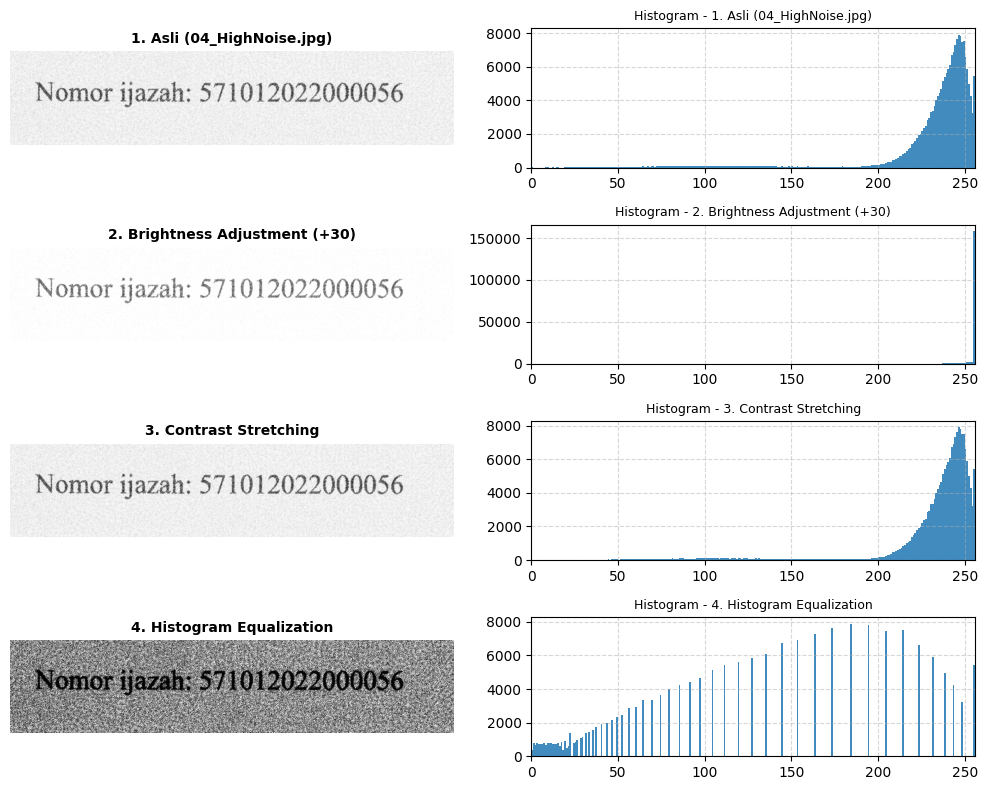


Memproses Gambar: 05_LowResolution_Upsampled.jpg


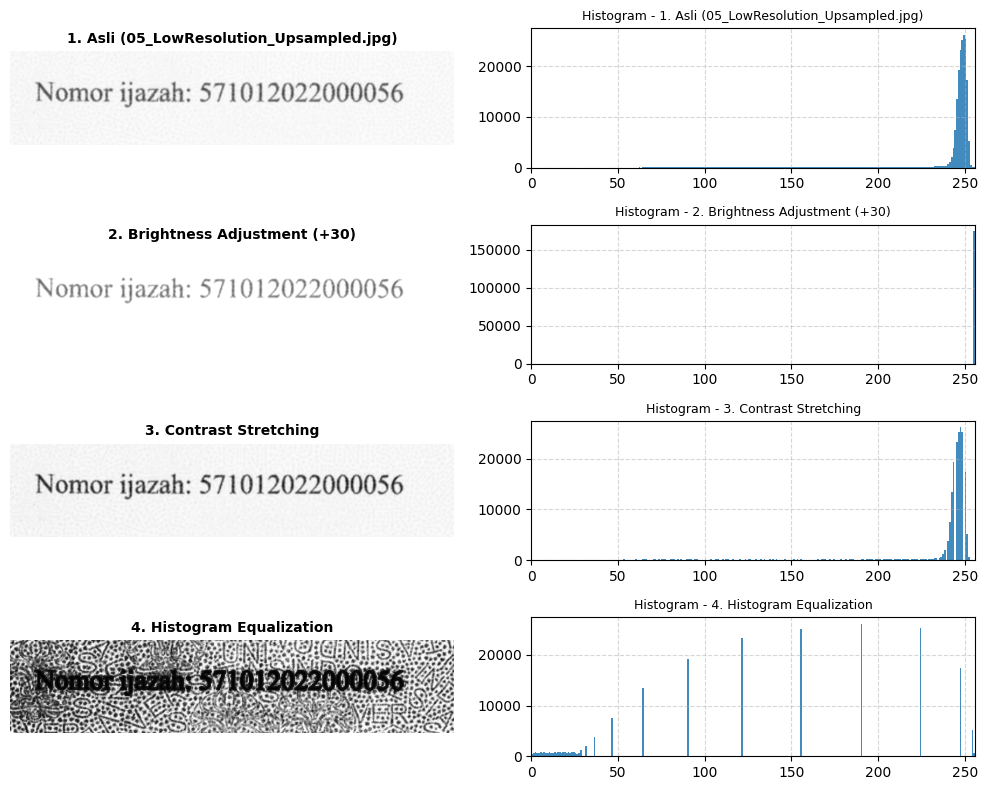


Memproses Gambar: 06_Faded_Underexposed.jpg


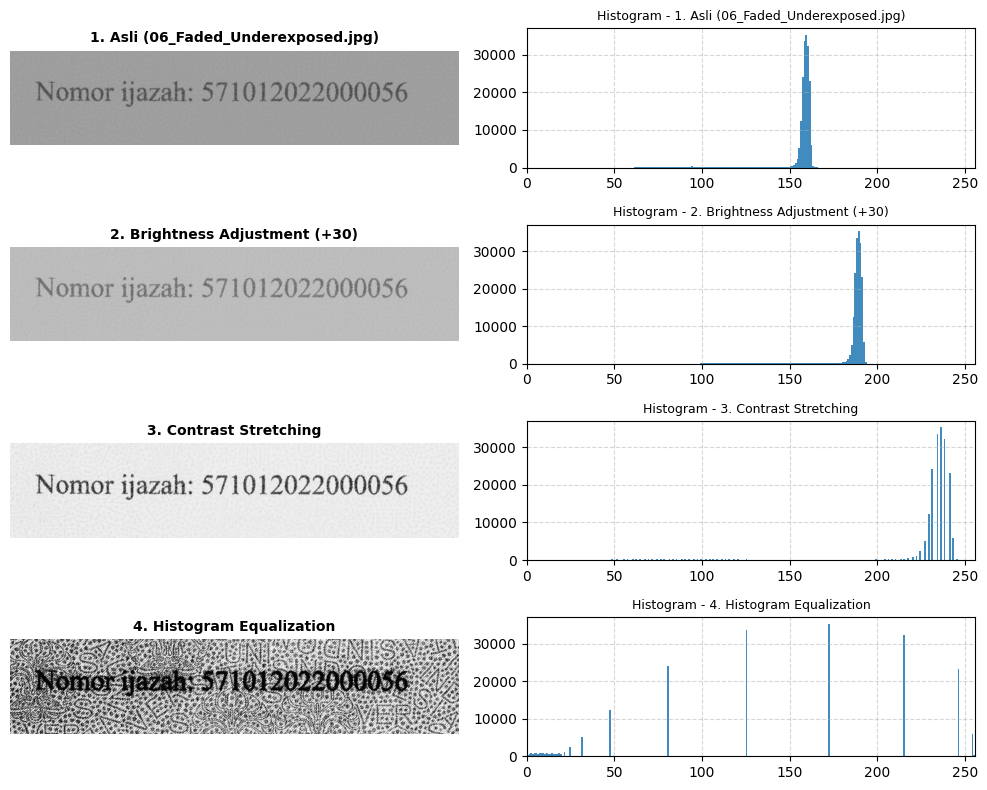


Memproses Gambar: 07_ColorShift_WarmTint.jpg


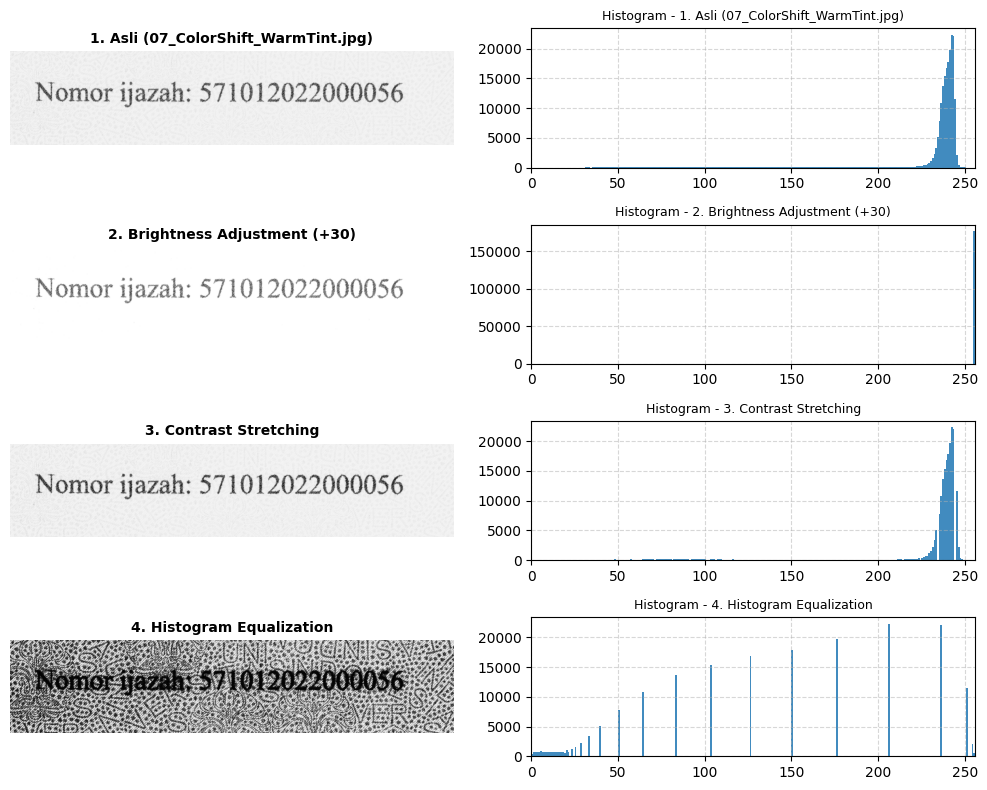


Memproses Gambar: 08_JPEGCompression_Artifacts.jpg


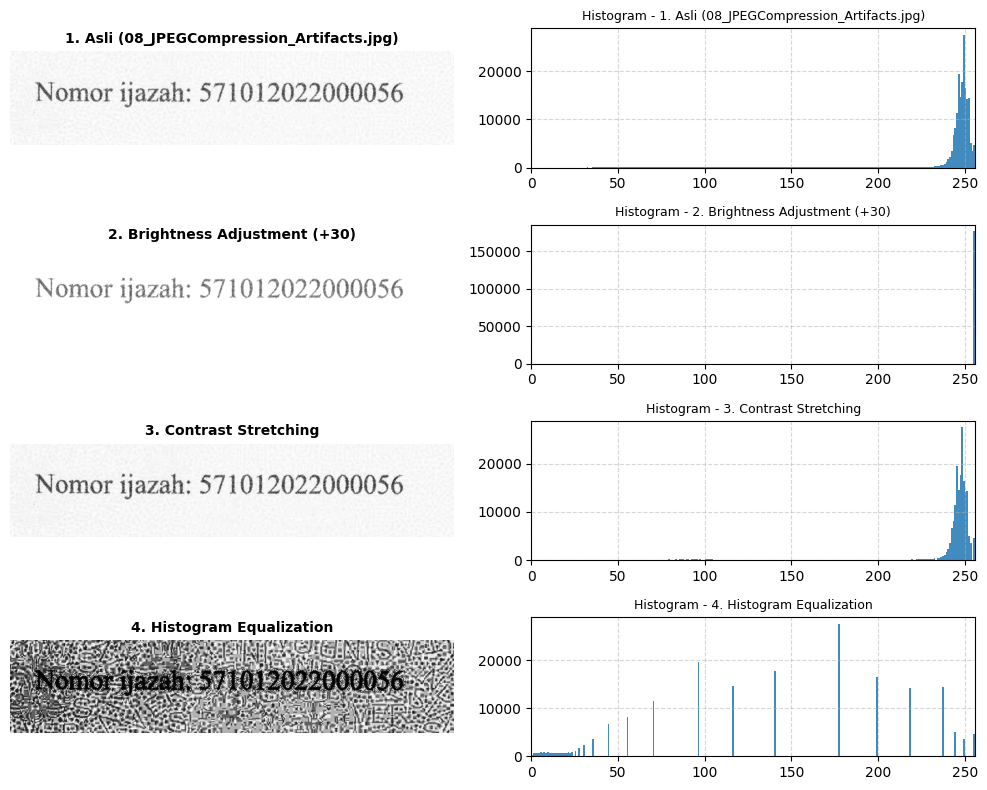


Memproses Gambar: 09_CombinedDegradation.jpg


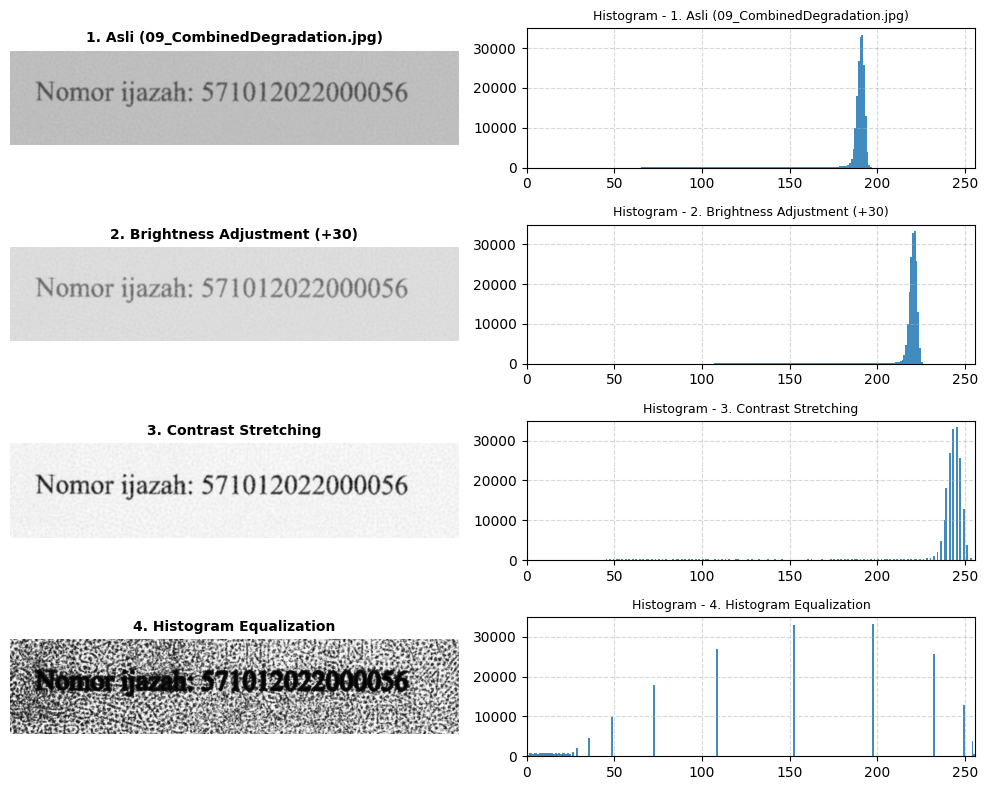

In [25]:
# 2. Iterasi / Ulangi proses untuk Setiap Gambar yang Ditemukan
for filename in image_files:
    print(f"\n=========================================")
    print(f"Memproses Gambar: {filename}")
    print(f"=========================================")
    
    # Gabungkan path folder dan nama file
    full_path = os.path.join(folder_path, filename)
    
    # Baca citra grayscale
    img = cv2.imread(full_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Gagal membaca gambar {filename}, melewati...")
        continue

    # Crop area nomor ijazah (Sesuaikan koordinat jika posisi gambar berbeda)
    # Pastikan koordinat tidak melebihi dimensi gambar asli
    h, w = img.shape
    ymin, ymax = min(2400, h), min(3350, h)
    xmin, xmax = min(2200, w), min(2400, w)
    
    crop = img[ymin:ymax, xmin:xmax]
    if crop.size == 0:
        print(f"Area crop kosong untuk {filename}, melewati...")
        continue
        
    orig = cv2.rotate(crop, cv2.ROTATE_90_CLOCKWISE)

    # Enhancement
    brightness = cv2.add(orig, 30)
    
    p_min, p_max = np.min(orig), np.max(orig)
    if p_max - p_min > 0:
        contrast_stretched = ((orig.astype(np.float32) - p_min) / (p_max - p_min) * 255.0).astype(np.uint8)
    else:
        contrast_stretched = orig.copy()
        
    hist_eq = cv2.equalizeHist(orig)

    # Plot Hasil per Gambar
    methods = [
        (f"1. Asli ({filename})", orig),
        ("2. Brightness Adjustment (+30)", brightness),
        ("3. Contrast Stretching", contrast_stretched),
        ("4. Histogram Equalization", hist_eq)
    ]

    fig, axes = plt.subplots(4, 2, figsize=(10, 8))

    for idx, (title, image) in enumerate(methods):
        axes[idx, 0].imshow(image, cmap='gray', vmin=0, vmax=255)
        axes[idx, 0].set_title(title, fontsize=10, fontweight='bold')
        axes[idx, 0].axis('off')
        
        axes[idx, 1].hist(image.ravel(), bins=256, range=[0, 256], color='#1f77b4', alpha=0.85)
        axes[idx, 1].set_title(f"Histogram - {title}", fontsize=9)
        axes[idx, 1].set_xlim([0, 256])
        axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()